# AeroPatch runs

Every benchmark run in `runs/`: what is running now, the D20 comparison of the untuned control
and the tuned v2 model, per-scenario results, timing, GPU memory and the history of all runs.

**Refresh: Run All.** The notebook only reads files in `runs/`; it starts and stops nothing.
Kernel: the `.venv-notebook` environment (Python 3.12 with ipykernel and matplotlib), kept apart
from the project's `.venv` so that the benchmark's environment does not change.

In [1]:
import json
import statistics
import time
from collections import defaultdict
from datetime import datetime
from math import comb
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.patches import Patch

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "runs").is_dir())
RUNS = ROOT / "runs"
LOG = RUNS / "d20-speed-and-test.log"
NOW = time.time()
TODAY = datetime.now().date()
D20_COMMIT = "c03f33f"  # the committed harness the D20 runs were planned on
CONTROL, V2 = "aeropatch-control", "aeropatch-v2-step64"
SHORT = {CONTROL: "control", V2: "v2 step 64"}

# The reference palette's first categorical slots; text in ink, grid and axes recessive.
INK, INK2, GRID, SURFACE, OTHER = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#a3a29c"
COLOR = {CONTROL: "#2a78d6", V2: "#eb6834", "untuned": "#2a78d6", "v2": "#eb6834", "v1": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10,
    "legend.frameon": False,
})


def table(columns, rows):
    head = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
    return Markdown("\n".join(head + ["| " + " | ".join(map(str, row)) + " |" for row in rows]))


def hm(ts):
    return datetime.fromtimestamp(ts).strftime("%H:%M")


def load(path):
    """One run file: header, attempts and results, plus progress read from its run folder."""
    head, attempts, results = {}, [], []
    for line in path.read_text(encoding="utf-8").splitlines():
        try:
            rec = json.loads(line)
        except json.JSONDecodeError:  # the torn last line of a killed run
            continue
        if rec.get("type") == "header":
            head = rec
        elif rec.get("type") == "attempt":
            attempts.append(rec)
        elif rec.get("type") == "result":
            results.append(rec)
    cfg = head.get("config", {})
    model = {"oracle": "reference fix", "frontier": cfg.get("frontier_model"),
             "cascade": f"{cfg.get('local_model')} + {cfg.get('frontier_model')}"}.get(cfg.get("mode"),
                                                                                       cfg.get("local_model"))
    folder = RUNS / path.stem
    finished = {r["task_id"]: (folder / r["task_id"] / "result.json").stat().st_mtime
                for r in results if (folder / r["task_id"] / "result.json").exists()}
    total = len(head.get("tasks", []))
    complete = bool(total) and len(results) >= total
    changed, current = path.stat().st_mtime, None
    if not complete and folder.is_dir():  # the scenario being worked on: a folder with no result.json yet
        newest = lambda d: max((f.stat().st_mtime for f in d.rglob("*")), default=d.stat().st_mtime)
        open_tasks = [d for d in folder.iterdir() if d.is_dir() and not (d / "result.json").exists()]
        if open_tasks:
            current = max(open_tasks, key=newest)
            changed = max(changed, newest(current))
    tok = [t for a in attempts if (t := ((a.get("proposal") or {}).get("usage") or {}).get("decode_tok_s"))]
    return {
        "id": path.stem, "config": cfg.get("name", "?"), "model": model, "split": head.get("split", "?"),
        "commit": (head.get("aeropatch_commit") or "?")[:7], "dirty": head.get("dirty"),
        "start": datetime.fromisoformat(head["time"]).astimezone() if head.get("time") else None,
        "total": total, "results": {r["task_id"]: r for r in results}, "attempts": attempts,
        "resolved": sum(bool(r["resolved"]) for r in results),
        "first": sum(1 for a in attempts if a.get("n") == 1 and a.get("label") == "RESOLVED"),
        "work_s": sum(r.get("duration_s") or 0 for r in results), "finished": finished,
        "status": "done" if complete else "running" if NOW - changed < 300 else "stopped",
        "changed": changed, "current": current, "tok_s": statistics.median(tok) if tok else None,
    }


runs = [load(p) for p in sorted(RUNS.glob("*.jsonl"))]
d20 = defaultdict(list)  # (split, model) -> runs in start order
for r in runs:
    if r["commit"] == D20_COMMIT and r["config"] == "repair-local":
        d20[r["split"], r["model"]].append(r)
print(f"{len(runs)} runs read at {datetime.now():%H:%M:%S}: "
      f"{sum(r['status'] == 'running' for r in runs)} running, {sum(r['status'] == 'stopped' for r in runs)} "
      f"stopped before the end, {sum(r['status'] == 'done' for r in runs)} complete")

111 runs read at 13:32:31: 0 running, 2 stopped before the end, 109 complete


## Right now

In [2]:
running = [r for r in runs if r["status"] == "running"]
for r in running:
    if not r["total"]:  # bench writes the header together with the first result
        display(Markdown(f"**Starting: `{r['id']}`**: its header and first result are not written yet."))
        continue
    done = len(r["results"])
    per = statistics.median([x.get("duration_s") or 0 for x in r["results"].values()]) if done else None
    eta = f", about {hm(NOW + per * (r['total'] - done))} to finish" if per else ""
    now_on = ""
    if r["current"] is not None:
        tries = sum(1 for d in r["current"].iterdir() if d.name.startswith("attempt_"))
        now_on = f"; on `{r['current'].name}`, attempt {tries}, last write {NOW - r['changed']:.0f} s ago"
    display(Markdown(f"**Running: `{r['id']}`**, {r['config']}, {r['model']}, {r['split']}: "
                     f"{done} of {r['total']} scenarios done, {r['resolved']} resolved{now_on}{eta}."))
if not running:
    display(Markdown("**No run has written anything in the last 5 minutes.**"))

# The D20 plan in its order: the two speed runs, then 2 runs per model on each test split, alternating.
PLAN = [("dev", CONTROL), ("dev", V2)] + [(s, m) for s in ("test", "test_b", "test_c") for _ in (1, 2)
                                          for m in (CONTROL, V2)]
seen, rows = defaultdict(int), []
for split, model in PLAN:
    i = seen[split, model]
    seen[split, model] += 1
    r = d20[split, model][i] if i < len(d20[split, model]) else None
    score = "" if r is None else f"{r['resolved']}/{len(r['results'])}" + (
        "" if r["status"] == "done" else f" (of {r['total']})")
    when = "" if r is None else f"{r['start']:%d %b %H:%M}"
    rows.append([split + (" (speed)" if split == "dev" else ""), SHORT[model], i + 1,
                 "queued" if r is None else r["status"], score, when, f"`{r['id']}`" if r else ""])
display(Markdown("### The D20 queue"))
display(table(["Split", "Model", "Run", "State", "Resolved", "Started", "Run ID"], rows))

if LOG.exists():
    marks = [l for l in LOG.read_text(encoding="utf-8", errors="replace").splitlines()
             if l.startswith(("===", "done", "tierbc", "peak VRAM"))]
    display(Markdown("### Last lines of `runs/d20-speed-and-test.log`\n\n```text\n" + "\n".join(marks[-8:]) + "\n```"))

**No run has written anything in the last 5 minutes.**

### The D20 queue

| Split | Model | Run | State | Resolved | Started | Run ID |
|---|---|---|---|---|---|---|
| dev (speed) | control | 1 | done | 9/13 | 14 Oct 12:19 | `20261014-121928-repair-local-dev` |
| dev (speed) | v2 step 64 | 1 | done | 8/13 | 14 Oct 12:24 | `20261014-122421-repair-local-dev` |
| test | control | 1 | done | 19/27 | 13 Oct 17:03 | `20261013-170329-repair-local-test` |
| test | v2 step 64 | 1 | done | 18/27 | 14 Oct 12:31 | `20261014-123112-repair-local-test` |
| test | control | 2 | done | 19/27 | 14 Oct 12:43 | `20261014-124302-repair-local-test` |
| test | v2 step 64 | 2 | done | 14/27 | 14 Oct 12:53 | `20261014-125354-repair-local-test` |
| test_b | control | 1 | done | 4/10 | 14 Oct 13:06 | `20261014-130652-repair-local-test_b` |
| test_b | v2 step 64 | 1 | done | 2/10 | 14 Oct 13:12 | `20261014-131242-repair-local-test_b` |
| test_b | control | 2 | done | 3/10 | 14 Oct 13:16 | `20261014-131647-repair-local-test_b` |
| test_b | v2 step 64 | 2 | done | 1/10 | 14 Oct 13:22 | `20261014-132226-repair-local-test_b` |
| test_c | control | 1 | done | 5/5 | 14 Oct 13:26 | `20261014-132647-repair-local-test_c` |
| test_c | v2 step 64 | 1 | done | 4/5 | 14 Oct 13:28 | `20261014-132803-repair-local-test_c` |
| test_c | control | 2 | done | 4/5 | 14 Oct 13:29 | `20261014-132909-repair-local-test_c` |
| test_c | v2 step 64 | 2 | done | 5/5 | 14 Oct 13:30 | `20261014-133016-repair-local-test_c` |

### Last lines of `runs/d20-speed-and-test.log`

```text
=== exit 0 13:28:01
=== test_c aeropatch-v2-step64 run 1 13:28:01
=== exit 0 13:29:07
=== test_c aeropatch-control run 2 13:29:07
=== exit 0 13:30:13
=== test_c aeropatch-v2-step64 run 2 13:30:13
=== exit 0 13:31:17
tierbc done 13:31:17
```

## D20: the pre-registered comparison

The rule, written on 2026-10-13 before any test run: **a gain** is v2 at least 4 above the
control on `test` (of 54) and not below it on `test_b`; **a loss** is at least 4 below on `test`;
anything else is **no difference shown**. Nothing is tuned afterwards on what these runs show.
The pooled McNemar pairs run *i* of the control with run *i* of v2, scenario by scenario.

In [3]:
def mcnemar(b, c):
    n = b + c
    return 1.0 if n == 0 else min(1.0, 2 * sum(comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)


def pooled(split):
    """Like for like: run i of the control against run i of v2, on the scenarios both have finished."""
    c, v = d20[split, CONTROL], d20[split, V2]
    rc_tot = rv_tot = pairs = only_c = only_v = 0
    for rc, rv in zip(c, v):
        for t in rc["results"].keys() & rv["results"].keys():
            a, b = bool(rc["results"][t]["resolved"]), bool(rv["results"][t]["resolved"])
            rc_tot, rv_tot, pairs = rc_tot + a, rv_tot + b, pairs + 1
            only_c, only_v = only_c + (a and not b), only_v + (b and not a)
    complete = len(c) == len(v) == 2 and all(r["status"] == "done" for r in c + v)
    return c, v, rc_tot, rv_tot, pairs, only_c, only_v, complete


tot = lambda rs: sum(r["resolved"] for r in rs)
n_of = lambda rs: sum(len(r["results"]) for r in rs)
rows, summary = [], {}
for split in ("test", "test_b", "test_c"):
    c, v, ct, vt, pairs, only_c, only_v, complete = pooled(split)
    summary[split] = (ct, vt, complete)
    rows.append([split, f"{tot(c)}/{n_of(c)} ({' + '.join(str(r['resolved']) for r in c) or '-'})",
                 f"{tot(v)}/{n_of(v)} ({' + '.join(str(r['resolved']) for r in v) or '-'})",
                 f"{ct} / {vt} of {pairs}", f"{vt - ct:+d}",
                 f"{sum(r['first'] for r in c)} / {sum(r['first'] for r in v)}",
                 f"{only_c} / {only_v}", f"{mcnemar(only_c, only_v):.3f}", "yes" if complete else "no"])
display(table(["Split", "Control, all its runs", "v2, all its runs", "Paired: control / v2", "v2 - control (paired)",
               "Attempt 1 (control / v2)", "Pairs one model only (control / v2)", "McNemar p (exact)",
               "All 4 runs done"], rows))

ct, vt, test_done = summary["test"]
cb, vb, b_done = summary["test_b"]
if vt - ct >= 4 and vb >= cb:
    verdict = "a gain"
elif ct - vt >= 4:
    verdict = "a loss"
else:
    verdict = "no difference shown"
if not test_done:
    n_done = sum(r["status"] == "done" for m in (CONTROL, V2) for r in d20["test", m])
    display(Markdown(f"**No verdict yet**: {n_done} of 4 test runs are done. Paired so far: v2 {vt - ct:+d} on test."))
elif verdict == "a gain" and not b_done:
    display(Markdown(f"**Test shows a gain ({vt - ct:+d} of 54); final once Tier B is done** (so far {vb - cb:+d})."))
else:
    display(Markdown(f"**By the rule: {verdict}** (test {vt - ct:+d} of 54, Tier B {vb - cb:+d} of 20)."))

| Split | Control, all its runs | v2, all its runs | Paired: control / v2 | v2 - control (paired) | Attempt 1 (control / v2) | Pairs one model only (control / v2) | McNemar p (exact) | All 4 runs done |
|---|---|---|---|---|---|---|---|---|
| test | 38/54 (19 + 19) | 32/54 (18 + 14) | 38 / 32 of 54 | -6 | 28 / 24 | 9 / 3 | 0.146 | yes |
| test_b | 7/20 (4 + 3) | 3/20 (2 + 1) | 7 / 3 of 20 | -4 | 4 / 3 | 6 / 2 | 0.289 | yes |
| test_c | 9/10 (5 + 4) | 9/10 (4 + 5) | 9 / 9 of 10 | +0 | 7 / 6 | 1 / 1 | 1.000 | yes |

**By the rule: a loss** (test -6 of 54, Tier B -4 of 20).

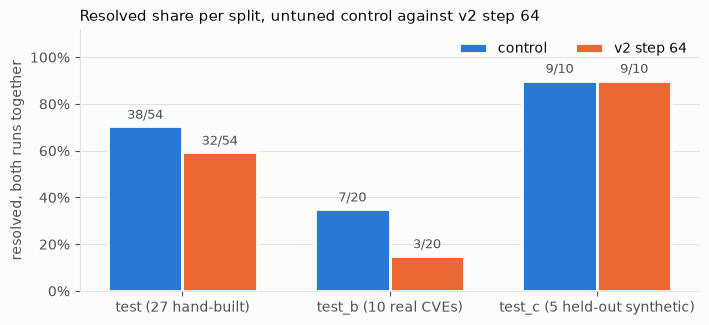

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
splits = ["test", "test_b", "test_c"]
for k, model in enumerate((CONTROL, V2)):
    for x, split in enumerate(splits):
        rs = d20[split, model]
        n = n_of(rs)
        if not n:
            if k == 0 and not n_of(d20[split, V2]):
                ax.text(x, 0.03, "not run yet", ha="center", va="bottom", color=INK2, fontsize=9)
            continue
        share = tot(rs) / n
        ax.bar(x + (k - 0.5) * 0.36, share, 0.36, color=COLOR[model], edgecolor=SURFACE, linewidth=2,
               label=SHORT[model] if x == 0 else None)
        ax.text(x + (k - 0.5) * 0.36, share + 0.02, f"{tot(rs)}/{n}", ha="center", va="bottom", color=INK2,
                fontsize=9)
ax.set_xticks(range(3), ["test (27 hand-built)", "test_b (10 real CVEs)", "test_c (5 held-out synthetic)"])
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_ylabel("resolved, both runs together")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncols=2)
ax.set_title("Resolved share per split, untuned control against v2 step 64", loc="left", fontsize=11)
plt.show()

## Per scenario (✓ resolved, otherwise the final label; **bold** where the two models' resolve shares differ)

In [5]:
for split in ("test", "test_b", "test_c"):
    c, v = d20[split, CONTROL], d20[split, V2]
    order = [r for pair in zip(c + [None] * 2, v + [None] * 2) for r in pair if r][:4]
    if not order:
        continue
    names = [f"{'C' if r['model'] == CONTROL else 'V'}{(c if r['model'] == CONTROL else v).index(r) + 1}" for r in order]
    tasks = sorted({t for r in order for t in r["results"]})
    rows = []
    for t in tasks:
        cells = [("✓" if r["results"][t]["resolved"] else r["results"][t]["label"]) if t in r["results"] else "…"
                 for r in order]
        done_c = [r for r in c if t in r["results"]]
        done_v = [r for r in v if t in r["results"]]
        nc = sum(bool(r["results"][t]["resolved"]) for r in done_c)
        nv = sum(bool(r["results"][t]["resolved"]) for r in done_v)
        differ = done_c and done_v and nc / len(done_c) != nv / len(done_v)
        rows.append([f"**{t}**" if differ else t, *cells, f"{nc}/{len(done_c)}", f"{nv}/{len(done_v)}"])
    display(Markdown(f"### {split}"))
    display(table(["Scenario", *names, "Control", "v2"], rows))

### test

| Scenario | C1 | V1 | C2 | V2 | Control | v2 |
|---|---|---|---|---|---|---|
| **A-020-01** | POC_STILL_FAILS | STUCK | ✓ | POC_STILL_FAILS | 1/2 | 0/2 |
| A-020-02 | ✓ | REGRESSION | POC_STILL_FAILS | ✓ | 1/2 | 1/2 |
| **A-022-03** | POC_STILL_FAILS | ✓ | POC_STILL_FAILS | POC_STILL_FAILS | 0/2 | 1/2 |
| A-078-03 | REGRESSION | GATE_REJECT | REGRESSION | FORMAT_FAIL | 0/2 | 0/2 |
| **A-078-04** | ✓ | STUCK | POC_STILL_FAILS | STUCK | 1/2 | 0/2 |
| A-079-02 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-079-03 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-089-03 | REGRESSION | REGRESSION | FORMAT_FAIL | REGRESSION | 0/2 | 0/2 |
| **A-089-04** | ✓ | ✓ | ✓ | STUCK | 2/2 | 1/2 |
| **A-1333-02** | ✓ | STUCK | ✓ | ✓ | 2/2 | 1/2 |
| A-209-02 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-327-01 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-327-02 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-328-02 | POC_STILL_FAILS | REGRESSION | POC_STILL_FAILS | REGRESSION | 0/2 | 0/2 |
| A-338-01 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-338-02 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-352-01 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-352-02 | POC_STILL_FAILS | ✓ | ✓ | POC_STILL_FAILS | 1/2 | 1/2 |
| A-502-02 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| **A-502-03** | ✓ | ✓ | ✓ | POC_STILL_FAILS | 2/2 | 1/2 |
| **A-601-02** | ✓ | ✓ | ✓ | STUCK | 2/2 | 1/2 |
| A-611-01 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-611-02 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| A-798-01 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| **A-798-02** | ✓ | ✓ | ✓ | REGRESSION | 2/2 | 1/2 |
| A-918-02 | GATE_REJECT | STUCK | GATE_REJECT | REGRESSION | 0/2 | 0/2 |
| A-918-03 | POC_STILL_FAILS | STUCK | POC_STILL_FAILS | STUCK | 0/2 | 0/2 |

### test_b

| Scenario | C1 | V1 | C2 | V2 | Control | v2 |
|---|---|---|---|---|---|---|
| **B-022-01** | ✓ | FORMAT_FAIL | ✓ | REGRESSION | 2/2 | 0/2 |
| B-079-01 | FORMAT_FAIL | REGRESSION | FORMAT_FAIL | POC_STILL_FAILS | 0/2 | 0/2 |
| **B-094-01** | REGRESSION | ✓ | STUCK | ✓ | 0/2 | 2/2 |
| **B-113-01** | ✓ | REGRESSION | GATE_REJECT | REGRESSION | 1/2 | 0/2 |
| B-1333-01 | STUCK | FORMAT_FAIL | STUCK | STUCK | 0/2 | 0/2 |
| **B-287-01** | ✓ | FORMAT_FAIL | ✓ | POC_STILL_FAILS | 2/2 | 0/2 |
| B-347-01 | ✓ | ✓ | GATE_REJECT | STUCK | 1/2 | 1/2 |
| B-347-02 | STUCK | STUCK | GATE_REJECT | REGRESSION | 0/2 | 0/2 |
| **B-400-01** | STUCK | REGRESSION | ✓ | FORMAT_FAIL | 1/2 | 0/2 |
| B-400-02 | POC_STILL_FAILS | STUCK | POC_STILL_FAILS | STUCK | 0/2 | 0/2 |

### test_c

| Scenario | C1 | V1 | C2 | V2 | Control | v2 |
|---|---|---|---|---|---|---|
| C-020-01 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| C-022-01 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| C-089-01 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| C-328-01 | ✓ | ✓ | ✓ | ✓ | 2/2 | 2/2 |
| C-601-01 | ✓ | POC_STILL_FAILS | POC_STILL_FAILS | ✓ | 1/2 | 1/2 |

## Today's timeline (each bar is one scenario, from its start to its result)

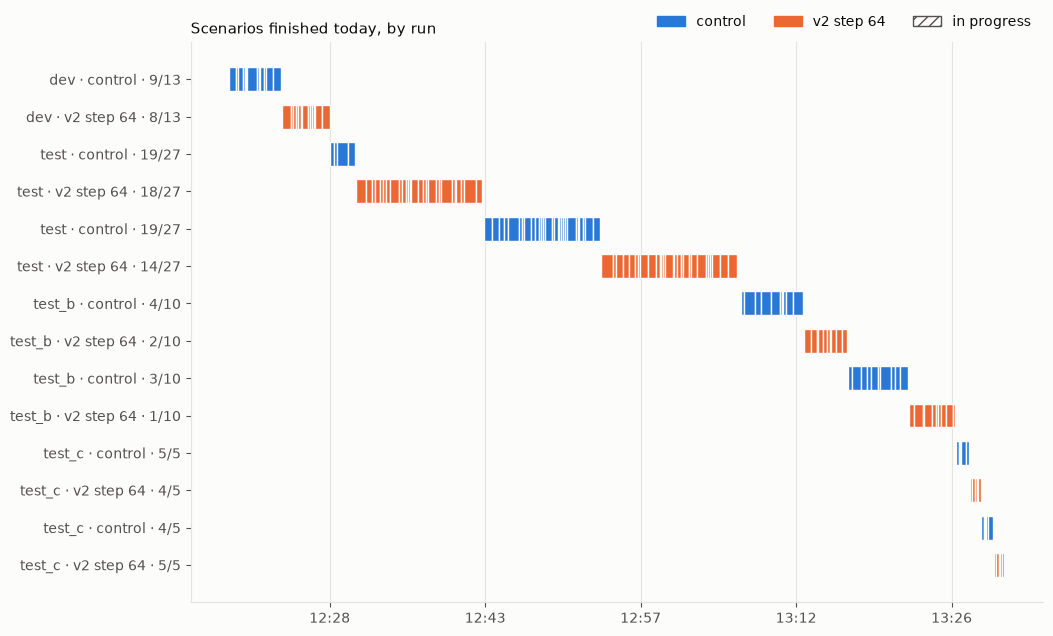

In [6]:
today = [r for r in runs if any(datetime.fromtimestamp(t).date() == TODAY for t in r["finished"].values())
         or r["status"] == "running"]
first_today = lambda r: min((t - (r["results"][k].get("duration_s") or 0) for k, t in r["finished"].items()
                             if datetime.fromtimestamp(t).date() == TODAY), default=NOW)
today.sort(key=first_today)  # in the order they ran today (a resumed run started on an earlier day)
if today:
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(today) + 1.4))
    for y, r in enumerate(today):
        spans = [(mdates.date2num(datetime.fromtimestamp(t - (r["results"][k].get("duration_s") or 0))),
                  (r["results"][k].get("duration_s") or 0) / 86400)
                 for k, t in r["finished"].items() if datetime.fromtimestamp(t).date() == TODAY]
        color = COLOR.get(r["model"], OTHER)
        ax.broken_barh(spans, (y - 0.32, 0.64), facecolors=color, edgecolor=SURFACE, linewidth=1)
        if r["status"] == "running":  # from the last result to now: the scenario being worked on
            last = max(r["finished"].values(), default=r["changed"])
            ax.broken_barh([(mdates.date2num(datetime.fromtimestamp(last)), (NOW - last) / 86400)],
                           (y - 0.32, 0.64), facecolors="none", edgecolor=color, hatch="///", linewidth=1)
    ax.set_yticks(range(len(today)),
                  [f"{r['split']} · {SHORT.get(r['model'], r['model'])} · {r['resolved']}/{r['total']}"
                   + (" · running" if r["status"] == "running" else "") for r in today])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Patch(color=COLOR[CONTROL], label="control"), Patch(color=COLOR[V2], label="v2 step 64"),
                       Patch(facecolor="none", edgecolor=INK2, hatch="///", label="in progress")],
              loc="lower right", bbox_to_anchor=(1, 1), ncols=3)
    ax.set_title("Scenarios finished today, by run", loc="left", fontsize=11)
    plt.show()
else:
    print("No scenario finished today.")

## Speed and GPU memory

Sampled every 0.5 s with `nvidia-smi` during the two speed runs. The drop near the start is
Ollama unloading the previous model before it loads this one. Decode speed is the median over
each run's attempts; the control's first test run ran yesterday with another program on the GPU.

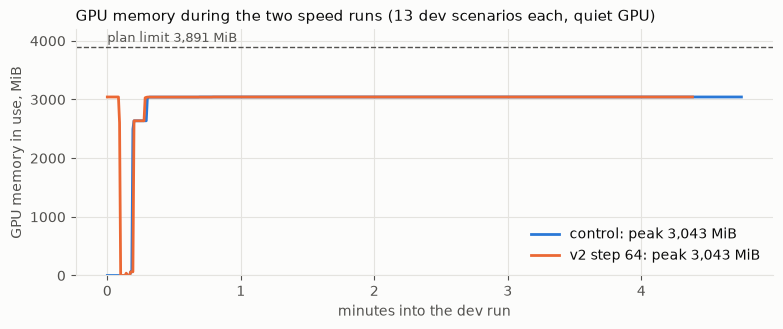

| Run | Model | Split | Resolved | Decode tok/s (median) | Scenario time, min |
|---|---|---|---|---|---|
| `20261013-170329-repair-local-test` | control | test | 19/27 | 28.4 | 14.5 |
| `20261014-121928-repair-local-dev` | control | dev | 9/13 | 46.5 | 4.8 |
| `20261014-122421-repair-local-dev` | v2 step 64 | dev | 8/13 | 46.7 | 4.4 |
| `20261014-123112-repair-local-test` | v2 step 64 | test | 18/27 | 46.3 | 11.7 |
| `20261014-124302-repair-local-test` | control | test | 19/27 | 46.2 | 10.7 |
| `20261014-125354-repair-local-test` | v2 step 64 | test | 14/27 | 46.6 | 12.6 |
| `20261014-130652-repair-local-test_b` | control | test_b | 4/10 | 46.2 | 5.7 |
| `20261014-131242-repair-local-test_b` | v2 step 64 | test_b | 2/10 | 46.8 | 4.0 |
| `20261014-131647-repair-local-test_b` | control | test_b | 3/10 | 46.5 | 5.6 |
| `20261014-132226-repair-local-test_b` | v2 step 64 | test_b | 1/10 | 46.9 | 4.3 |
| `20261014-132647-repair-local-test_c` | control | test_c | 5/5 | 47.3 | 1.2 |
| `20261014-132803-repair-local-test_c` | v2 step 64 | test_c | 4/5 | 47.5 | 1.0 |
| `20261014-132909-repair-local-test_c` | control | test_c | 4/5 | 47.3 | 1.1 |
| `20261014-133016-repair-local-test_c` | v2 step 64 | test_c | 5/5 | 47.2 | 1.0 |

In [7]:
traces = {m: RUNS / f"vram-{m}.txt" for m in (CONTROL, V2)}
traces = {m: [int(x) for x in p.read_text().split() if x.isdigit()] for m, p in traces.items() if p.exists()}
if traces:
    fig, ax = plt.subplots(figsize=(9, 3.2))
    for m, mib in traces.items():
        xs = [i / 2 / 60 for i in range(len(mib))]  # one sample every 0.5 s
        ax.plot(xs, mib, color=COLOR[m], linewidth=2, label=f"{SHORT[m]}: peak {max(mib):,} MiB")
    ax.axhline(3891, color=INK2, linestyle="--", linewidth=1)
    ax.text(0, 3891 + 40, "plan limit 3,891 MiB", color=INK2, fontsize=9, va="bottom")
    ax.set_ylim(0, 4200)
    ax.set_xlabel("minutes into the dev run")
    ax.set_ylabel("GPU memory in use, MiB")
    ax.legend(loc="lower right")
    ax.set_title("GPU memory during the two speed runs (13 dev scenarios each, quiet GPU)", loc="left",
                 fontsize=11)
    plt.show()

rows = [[f"`{r['id']}`", SHORT.get(r["model"], r["model"]), r["split"], f"{r['resolved']}/{len(r['results'])}",
         "-" if r["tok_s"] is None else f"{r['tok_s']:.1f}", f"{r['work_s'] / 60:.1f}"]
        for r in runs if r in today]
display(table(["Run", "Model", "Split", "Resolved", "Decode tok/s (median)", "Scenario time, min"], rows))

## History: every `repair-local` run of a local model on dev

Untuned is the library `qwen3.5:4b` and the exported `aeropatch-control`; v1 and v2 are the
checkpoints of the two training runs. Up to 3 attempts each; full runs on committed code only.
Dev had 10 scenarios until 2026-10-01 and 13 after.

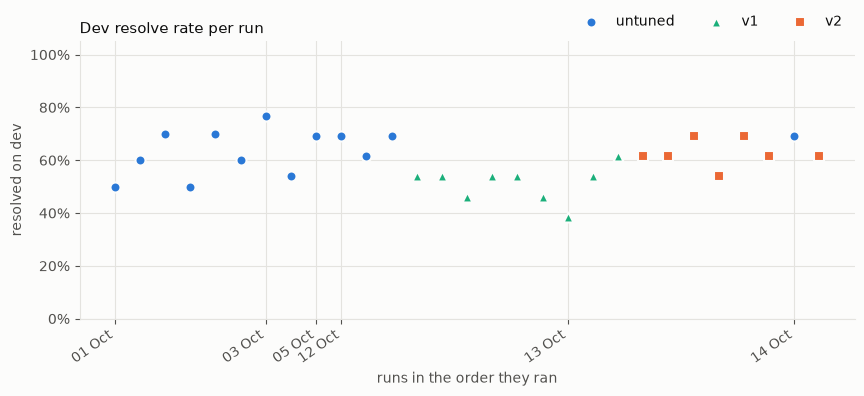

| Run | Model | Resolved | Attempt 1 |
|---|---|---|---|
| `20261001-163033-repair-local-dev` | qwen3.5:4b | 5/10 | 5 |
| `20261001-163541-repair-local-dev` | qwen3.5:4b | 6/10 | 6 |
| `20261001-164317-repair-local-dev` | qwen3.5:4b | 7/10 | 5 |
| `20261001-164919-repair-local-dev` | qwen3.5:4b | 5/10 | 5 |
| `20261001-165311-repair-local-dev` | qwen3.5:4b | 7/10 | 5 |
| `20261001-171411-repair-local-dev` | qwen3.5:4b | 6/10 | 5 |
| `20261003-113223-repair-local-dev` | qwen3.5:4b | 10/13 | 7 |
| `20261003-115043-repair-local-dev` | qwen3.5:4b | 7/13 | 7 |
| `20261005-150539-repair-local-dev-killed` | qwen3.5:4b | 9/13 | 8 |
| `20261012-164903-repair-local-dev` | aeropatch-control | 9/13 | 8 |
| `20261012-171355-repair-local-dev` | aeropatch-control | 8/13 | 7 |
| `20261012-171917-repair-local-dev` | aeropatch-control | 9/13 | 8 |
| `20261012-201541-repair-local-dev` | aeropatch-step64 | 7/13 | 5 |
| `20261012-201954-repair-local-dev` | aeropatch-step64 | 7/13 | 5 |
| `20261012-202425-repair-local-dev` | aeropatch-step64 | 6/13 | 5 |
| `20261012-202913-repair-local-dev` | aeropatch-step128 | 7/13 | 6 |
| `20261012-203246-repair-local-dev` | aeropatch-step128 | 7/13 | 5 |
| `20261012-203620-repair-local-dev` | aeropatch-step128 | 6/13 | 5 |
| `20261013-105642-repair-local-dev` | aeropatch-step32 | 5/13 | 3 |
| `20261013-110052-repair-local-dev` | aeropatch-step32 | 7/13 | 3 |
| `20261013-110550-repair-local-dev` | aeropatch-step32 | 8/13 | 5 |
| `20261013-151854-repair-local-dev` | aeropatch-v2-step64 | 8/13 | 5 |
| `20261013-152453-repair-local-dev` | aeropatch-v2-step128 | 8/13 | 8 |
| `20261013-153130-repair-local-dev` | aeropatch-v2-step64 | 9/13 | 7 |
| `20261013-153655-repair-local-dev` | aeropatch-v2-step128 | 7/13 | 7 |
| `20261013-154255-repair-local-dev` | aeropatch-v2-step64 | 9/13 | 6 |
| `20261013-154843-repair-local-dev` | aeropatch-v2-step128 | 8/13 | 8 |
| `20261014-121928-repair-local-dev` | aeropatch-control | 9/13 | 8 |
| `20261014-122421-repair-local-dev` | aeropatch-v2-step64 | 8/13 | 6 |

In [8]:
def family(model):
    if model in ("qwen3.5:4b", CONTROL):
        return "untuned"
    if str(model).startswith("aeropatch-v2"):
        return "v2"
    return "v1" if str(model).startswith("aeropatch-step") else None


MARK = {"untuned": "o", "v1": "^", "v2": "s"}
# Full runs on committed code only: the debugging runs of 2026-10-01 had 1 to 3 scenarios or a dirty tree.
hist = [r for r in runs if r["config"] == "repair-local" and r["split"] == "dev" and r["status"] == "done"
        and family(r["model"]) and r["total"] >= 10 and not r["dirty"]]
fig, ax = plt.subplots(figsize=(10, 3.6))
for fam in ("untuned", "v1", "v2"):
    pts = [(i, r["resolved"] / r["total"]) for i, r in enumerate(hist) if family(r["model"]) == fam]
    if pts:
        ax.scatter(*zip(*pts), s=52, marker=MARK[fam], color=COLOR[fam], edgecolor=SURFACE, linewidth=1.5,
                   label=fam, zorder=3)
days = {}  # the first run of each day carries the day's tick
for i, r in enumerate(hist):
    days.setdefault(r["start"].date(), i)
ax.set_xticks(list(days.values()), [f"{d:%d %b}" for d in days], rotation=35, ha="right")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("runs in the order they ran")
ax.set_ylabel("resolved on dev")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=3)
ax.set_title("Dev resolve rate per run", loc="left", fontsize=11)
plt.show()

display(table(["Run", "Model", "Resolved", "Attempt 1"],
              [[f"`{r['id']}`", r["model"], f"{r['resolved']}/{r['total']}", r["first"]] for r in hist]))

## All runs

In [9]:
display(table(["Run", "Started", "Config", "Model", "Split", "Commit", "Dirty", "State", "Resolved", "Attempt 1",
               "Scenario time, min", "tok/s"],
              [[f"`{r['id']}`", f"{r['start']:%d %b %H:%M}" if r["start"] else "?", r["config"], r["model"],
                r["split"], f"`{r['commit']}`", "yes" if r["dirty"] else "no", r["status"],
                f"{r['resolved']}/{len(r['results'])}" + ("" if r["status"] == "done" else f" (of {r['total']})"),
                r["first"], f"{r['work_s'] / 60:.1f}", "-" if r["tok_s"] is None else f"{r['tok_s']:.1f}"]
               for r in reversed(runs)]))

| Run | Started | Config | Model | Split | Commit | Dirty | State | Resolved | Attempt 1 | Scenario time, min | tok/s |
|---|---|---|---|---|---|---|---|---|---|---|---|
| `20261014-133016-repair-local-test_c` | 14 Oct 13:30 | repair-local | aeropatch-v2-step64 | test_c | `c03f33f` | no | done | 5/5 | 3 | 1.0 | 47.2 |
| `20261014-132909-repair-local-test_c` | 14 Oct 13:29 | repair-local | aeropatch-control | test_c | `c03f33f` | no | done | 4/5 | 4 | 1.1 | 47.3 |
| `20261014-132803-repair-local-test_c` | 14 Oct 13:28 | repair-local | aeropatch-v2-step64 | test_c | `c03f33f` | no | done | 4/5 | 3 | 1.0 | 47.5 |
| `20261014-132647-repair-local-test_c` | 14 Oct 13:26 | repair-local | aeropatch-control | test_c | `c03f33f` | no | done | 5/5 | 3 | 1.2 | 47.3 |
| `20261014-132226-repair-local-test_b` | 14 Oct 13:22 | repair-local | aeropatch-v2-step64 | test_b | `c03f33f` | no | done | 1/10 | 1 | 4.3 | 46.9 |
| `20261014-131647-repair-local-test_b` | 14 Oct 13:16 | repair-local | aeropatch-control | test_b | `c03f33f` | no | done | 3/10 | 1 | 5.6 | 46.5 |
| `20261014-131242-repair-local-test_b` | 14 Oct 13:12 | repair-local | aeropatch-v2-step64 | test_b | `c03f33f` | no | done | 2/10 | 2 | 4.0 | 46.8 |
| `20261014-130652-repair-local-test_b` | 14 Oct 13:06 | repair-local | aeropatch-control | test_b | `c03f33f` | no | done | 4/10 | 3 | 5.7 | 46.2 |
| `20261014-125354-repair-local-test` | 14 Oct 12:53 | repair-local | aeropatch-v2-step64 | test | `c03f33f` | no | done | 14/27 | 11 | 12.6 | 46.6 |
| `20261014-124302-repair-local-test` | 14 Oct 12:43 | repair-local | aeropatch-control | test | `c03f33f` | no | done | 19/27 | 14 | 10.7 | 46.2 |
| `20261014-123112-repair-local-test` | 14 Oct 12:31 | repair-local | aeropatch-v2-step64 | test | `c03f33f` | no | done | 18/27 | 13 | 11.7 | 46.3 |
| `20261014-122421-repair-local-dev` | 14 Oct 12:24 | repair-local | aeropatch-v2-step64 | dev | `c03f33f` | no | done | 8/13 | 6 | 4.4 | 46.7 |
| `20261014-121928-repair-local-dev` | 14 Oct 12:19 | repair-local | aeropatch-control | dev | `c03f33f` | no | done | 9/13 | 8 | 4.8 | 46.5 |
| `20261013-170329-repair-local-test` | 13 Oct 17:03 | repair-local | aeropatch-control | test | `c03f33f` | no | done | 19/27 | 14 | 14.5 | 28.4 |
| `20261013-154843-repair-local-dev` | 13 Oct 15:48 | repair-local | aeropatch-v2-step128 | dev | `f43f77a` | no | done | 8/13 | 8 | 6.2 | 28.8 |
| `20261013-154255-repair-local-dev` | 13 Oct 15:42 | repair-local | aeropatch-v2-step64 | dev | `f43f77a` | no | done | 9/13 | 6 | 5.7 | 28.8 |
| `20261013-153655-repair-local-dev` | 13 Oct 15:36 | repair-local | aeropatch-v2-step128 | dev | `f43f77a` | no | done | 7/13 | 7 | 5.9 | 28.8 |
| `20261013-153130-repair-local-dev` | 13 Oct 15:31 | repair-local | aeropatch-v2-step64 | dev | `f43f77a` | no | done | 9/13 | 7 | 5.3 | 28.8 |
| `20261013-152453-repair-local-dev` | 13 Oct 15:24 | repair-local | aeropatch-v2-step128 | dev | `f43f77a` | no | done | 8/13 | 8 | 6.5 | 28.7 |
| `20261013-151854-repair-local-dev` | 13 Oct 15:18 | repair-local | aeropatch-v2-step64 | dev | `f43f77a` | no | done | 8/13 | 5 | 5.9 | 28.8 |
| `20261013-112755-prefill-control-plan-dev` | 13 Oct 11:27 | prefill-control-plan | aeropatch-step64 | dev | `f43f77a` | yes | done | 5/13 | 5 | 1.6 | 48.3 |
| `20261013-112600-prefill-control-plan-dev` | 13 Oct 11:26 | prefill-control-plan | aeropatch-control | dev | `f43f77a` | yes | done | 7/13 | 7 | 1.8 | 47.8 |
| `20261013-112406-prefill-control-plan-dev` | 13 Oct 11:24 | prefill-control-plan | aeropatch-step64 | dev | `f43f77a` | yes | done | 6/13 | 6 | 1.8 | 48.2 |
| `20261013-112212-prefill-control-plan-dev` | 13 Oct 11:22 | prefill-control-plan | aeropatch-control | dev | `f43f77a` | yes | done | 6/13 | 6 | 1.8 | 48.3 |
| `20261013-112025-prefill-control-plan-dev` | 13 Oct 11:20 | prefill-control-plan | aeropatch-step64 | dev | `f43f77a` | yes | done | 5/13 | 5 | 1.7 | 48.3 |
| `20261013-111826-prefill-control-plan-dev` | 13 Oct 11:18 | prefill-control-plan | aeropatch-control | dev | `f43f77a` | yes | done | 7/13 | 7 | 1.9 | 47.9 |
| `20261013-110550-repair-local-dev` | 13 Oct 11:05 | repair-local | aeropatch-step32 | dev | `f43f77a` | no | done | 8/13 | 5 | 3.9 | 47.1 |
| `20261013-110052-repair-local-dev` | 13 Oct 11:00 | repair-local | aeropatch-step32 | dev | `f43f77a` | no | done | 7/13 | 3 | 4.8 | 47.3 |
| `20261013-105642-repair-local-dev` | 13 Oct 10:56 | repair-local | aeropatch-step32 | dev | `f43f77a` | no | done | 5/13 | 3 | 4.1 | 47.4 |
| `20261013-105029-prefill-finding-dev` | 13 Oct 10:50 | prefill-finding | aeropatch-control | dev | `f43f77a` | yes | done | 6/13 | 5 | 3.9 | 47.5 |
| `20261013-104622-prefill-plan-dev` | 13 Oct 10:46 | prefill-plan | aeropatch-control | dev | `f43f77a` | yes | done | 9/13 | 7 | 4.0 | 47.3 |
| `20261013-104224-prefill-finding-dev` | 13 Oct 10:42 | prefill-finding | aeropatch-control | dev | `f43f77a` | yes | done | 8/13 | 6 | 3.9 | 47.5 |
| `20261013-103745-prefill-plan-dev` | 13 Oct 10:37 | prefill-plan | aeropatch-control | dev | `f43f77a` | yes | done | 9/13 | 7 | 4.5 | 46.7 |
| `20261013-103404-prefill-finding-dev` | 13 Oct 10:34 | prefill-finding | aeropatch-control | dev | `f43f77a` | yes | done | 7/13 | 6 | 3.6 | 47.0 |
| `20261013-102945-prefill-plan-dev` | 13 Oct 10:29 | prefill-plan | aeropatch-control | dev | `f43f77a` | yes | done | 8/13 | 7 | 4.2 | 46.1 |
| `20261012-203620-repair-local-dev` | 12 Oct 20:36 | repair-local | aeropatch-step128 | dev | `978d0e1` | no | done | 6/13 | 5 | 3.3 | 47.3 |
| `20261012-203246-repair-local-dev` | 12 Oct 20:32 | repair-local | aeropatch-step128 | dev | `978d0e1` | no | done | 7/13 | 5 | 3.5 | 47.7 |
| `20261012-202913-repair-local-dev` | 12 Oct 20:29 | repair-local | aeropatch-step128 | dev | `978d0e1` | no | done | 7/13 | 6 | 3.4 | 47.7 |
| `20261012-202425-repair-local-dev` | 12 Oct 20:24 | repair-local | aeropatch-step64 | dev | `978d0e1` | no | done | 6/13 | 5 | 3.6 | 47.6 |
| `20261012-201954-repair-local-dev` | 12 Oct 20:19 | repair-local | aeropatch-step64 | dev | `978d0e1` | no | done | 7/13 | 5 | 4.4 | 47.4 |
| `20261012-201541-repair-local-dev` | 12 Oct 20:15 | repair-local | aeropatch-step64 | dev | `978d0e1` | no | done | 7/13 | 5 | 4.1 | 47.3 |
| `20261012-171917-repair-local-dev` | 12 Oct 17:19 | repair-local | aeropatch-control | dev | `97ae347` | no | done | 9/13 | 8 | 4.7 | 46.8 |
| `20261012-171355-repair-local-dev` | 12 Oct 17:13 | repair-local | aeropatch-control | dev | `97ae347` | no | done | 8/13 | 7 | 5.3 | 47.1 |
| `20261012-164903-repair-local-dev` | 12 Oct 16:49 | repair-local | aeropatch-control | dev | `cd65efa` | no | done | 9/13 | 8 | 4.8 | 46.9 |
| `20261009-student-pass` | 09 Oct 10:48 | repair-local | qwen3.5:4b | train | `4c43b51` | no | done | 156/189 | 111 | 54.2 | 47.4 |
| `20261006-154009-oracle-test_c` | 06 Oct 15:40 | oracle | reference fix | test_c | `1cdaebc` | yes | done | 5/5 | 5 | 0.3 | - |
| `20261006-153122-oracle-test_c` | 06 Oct 15:31 | oracle | reference fix | test_c | `1cdaebc` | yes | done | 5/5 | 5 | 0.3 | - |
| `20261006-153054-oracle-test_c` | 06 Oct 15:30 | oracle | reference fix | test_c | `1cdaebc` | yes | done | 5/5 | 5 | 0.3 | - |
| `20261005-201324-oracle-test_b` | 05 Oct 20:13 | oracle | reference fix | test_b | `97e5fa8` | no | done | 10/10 | 10 | 0.4 | - |
| `20261005-201131-oracle-test` | 05 Oct 20:11 | oracle | reference fix | test | `97e5fa8` | no | done | 27/27 | 27 | 1.8 | - |
| `20261005-201044-oracle-dev` | 05 Oct 20:10 | oracle | reference fix | dev | `97e5fa8` | no | done | 13/13 | 13 | 0.7 | - |
| `20261005-161537-repair-local-test_b` | 05 Oct 16:15 | repair-local | qwen3.5:4b | test_b | `e382773` | no | done | 5/10 | 5 | 4.4 | 45.5 |
| `20261005-160808-cascade-claude-code-test_b` | 05 Oct 16:08 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | test_b | `e382773` | no | done | 10/10 | 3 | 7.4 | 40.1 |
| `20261005-160526-repair-claude-code-test_b` | 05 Oct 16:05 | repair-claude-code | claude-opus-5 | test_b | `e382773` | no | done | 10/10 | 9 | 2.6 | - |
| `20261005-160032-repair-local-test_b` | 05 Oct 16:00 | repair-local | qwen3.5:4b | test_b | `e382773` | no | done | 5/10 | 4 | 4.8 | 47.1 |
| `20261005-160005-oracle-test_b` | 05 Oct 16:00 | oracle | reference fix | test_b | `e382773` | no | done | 10/10 | 10 | 0.4 | - |
| `20261005-150539-repair-local-dev-killed` | 05 Oct 15:05 | repair-local | qwen3.5:4b | dev | `2b03f0c` | no | done | 9/13 | 8 | 4.8 | 47.5 |
| `20261003-165008-cascade-claude-code-test` | 03 Oct 16:50 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | test | `9fcc75c` | no | done | 27/27 | 13 | 13.9 | 42.2 |
| `20261003-164740-oracle-test` | 03 Oct 16:47 | oracle | reference fix | test | `55e0709` | yes | done | 27/27 | 27 | 1.9 | - |
| `20261003-164650-oracle-dev` | 03 Oct 16:46 | oracle | reference fix | dev | `55e0709` | yes | done | 13/13 | 13 | 0.8 | - |
| `20261003-162838-repair-local-test` | 03 Oct 16:28 | repair-local | qwen3.5:4b | test | `55e0709` | no | done | 18/27 | 11 | 13.0 | 44.5 |
| `20261003-161702-cascade-claude-code-test` | 03 Oct 16:17 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | test | `55e0709` | no | done | 26/27 | 13 | 11.0 | 45.5 |
| `20261003-161129-repair-claude-code-test` | 03 Oct 16:11 | repair-claude-code | claude-opus-5 | test | `55e0709` | no | done | 27/27 | 27 | 5.2 | - |
| `20261003-155954-repair-local-test` | 03 Oct 15:59 | repair-local | qwen3.5:4b | test | `55e0709` | no | done | 17/27 | 12 | 11.3 | 48.0 |
| `20261003-155826-oracle-test-jobs2` | 03 Oct 15:58 | oracle | reference fix | test | `55e0709` | no | done | 27/27 | 27 | 1.9 | - |
| `20261003-124014-oracle-dev` | 03 Oct 12:40 | oracle | reference fix | dev | `3d26b27` | yes | done | 13/13 | 13 | 0.8 | - |
| `20261003-123850-oracle-test` | 03 Oct 12:38 | oracle | reference fix | test | `3d26b27` | yes | done | 20/20 | 20 | 1.3 | - |
| `20261003-122450-oracle-test` | 03 Oct 12:24 | oracle | reference fix | test | `3d26b27` | yes | done | 15/15 | 15 | 1.0 | - |
| `20261003-122433-oracle-test` | 03 Oct 12:24 | oracle | reference fix | test | `3d26b27` | yes | done | 1/1 | 1 | 0.1 | - |
| `20261003-121220-oracle-test` | 03 Oct 12:12 | oracle | reference fix | test | `3d26b27` | yes | done | 15/15 | 15 | 1.0 | - |
| `20261003-121131-oracle-dev` | 03 Oct 12:11 | oracle | reference fix | dev | `3d26b27` | yes | done | 13/13 | 13 | 0.8 | - |
| `20261003-115043-repair-local-dev` | 03 Oct 11:50 | repair-local | qwen3.5:4b | dev | `3d26b27` | no | done | 7/13 | 7 | 6.3 | 45.5 |
| `20261003-114259-cascade-claude-code-dev` | 03 Oct 11:43 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | dev | `3d26b27` | no | done | 13/13 | 7 | 7.6 | 45.7 |
| `20261003-113658-repair-claude-code-dev` | 03 Oct 11:36 | repair-claude-code | claude-opus-5 | dev | `3d26b27` | no | done | 13/13 | 13 | 5.7 | - |
| `20261003-113223-repair-local-dev` | 03 Oct 11:32 | repair-local | qwen3.5:4b | dev | `3d26b27` | no | done | 10/13 | 7 | 4.5 | 43.1 |
| `20261003-113134-oracle-dev` | 03 Oct 11:31 | oracle | reference fix | dev | `3d26b27` | no | done | 12/13 | 12 | 0.8 | - |
| `20261001-182901-cascade-claude-code-dev` | 01 Oct 18:29 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | dev | `f65332f` | yes | stopped | 0/0 (of 13) | 0 | 0.0 | - |
| `20261001-182615-repair-claude-code-dev` | 01 Oct 18:26 | repair-claude-code | claude-opus-5 | dev | `f65332f` | yes | done | 13/13 | 13 | 2.7 | - |
| `20261001-182050-repair-local-dev` | 01 Oct 18:20 | repair-local | qwen3.5:4b | dev | `f65332f` | yes | done | 8/13 | 7 | 5.3 | 43.0 |
| `20261001-181502-repair-local-dev` | 01 Oct 18:15 | repair-local | qwen3.5:4b | dev | `f65332f` | yes | done | 10/13 | 7 | 5.7 | 38.0 |
| `20261001-180638-cascade-claude-code-dev` | 01 Oct 18:06 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | dev | `f65332f` | yes | done | 13/13 | 7 | 4.8 | 47.8 |
| `20261001-180131-repair-claude-code-dev` | 01 Oct 18:01 | repair-claude-code | claude-opus-5 | dev | `f65332f` | yes | done | 13/13 | 12 | 4.9 | - |
| `20261001-175545-repair-local-dev` | 01 Oct 17:55 | repair-local | qwen3.5:4b | dev | `f65332f` | yes | done | 9/13 | 6 | 5.4 | 47.5 |
| `20261001-175057-repair-local-dev` | 01 Oct 17:50 | repair-local | qwen3.5:4b | dev | `f65332f` | yes | done | 8/13 | 6 | 4.7 | 47.8 |
| `20261001-174230-repair-local-dev` | 01 Oct 17:42 | repair-local | qwen3.5:4b | dev | `f65332f` | yes | done | 7/13 | 6 | 5.5 | 47.4 |
| `20261001-173918-repair-local-dev` | 01 Oct 17:39 | repair-local | qwen3.5:4b | dev | `f65332f` | yes | done | 0/1 | 0 | 0.4 | 48.0 |
| `20261001-173825-repair-local-dev` | 01 Oct 17:38 | repair-local | qwen3.5:4b | dev | `f65332f` | yes | done | 0/1 | 0 | 0.8 | 47.6 |
| `20261001-173632-repair-local-dev` | 01 Oct 17:36 | repair-local | qwen3.5:4b | dev | `f65332f` | yes | done | 2/3 | 2 | 0.4 | 48.1 |
| `20261001-173544-repair-local-dev` | 01 Oct 17:35 | repair-local | qwen3.5:4b | dev | `f65332f` | yes | done | 2/3 | 2 | 0.7 | 48.4 |
| `20261001-171411-repair-local-dev` | 01 Oct 17:14 | repair-local | qwen3.5:4b | dev | `f65332f` | no | done | 6/10 | 5 | 4.3 | 47.1 |
| `20261001-170856-cascade-claude-code-dev` | 01 Oct 17:08 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | dev | `f65332f` | no | done | 10/10 | 5 | 3.6 | 44.2 |
| `20261001-170839-repair-claude-code-dev` | 01 Oct 17:08 | repair-claude-code | claude-opus-5 | dev | `f65332f` | no | done | 1/1 | 1 | 0.2 | - |
| `20261001-170343-cascade-claude-code-dev` | 01 Oct 17:03 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | dev | `f65332f` | no | done | 9/10 | 5 | 3.8 | 48.9 |
| `20261001-165958-repair-claude-code-dev` | 01 Oct 16:59 | repair-claude-code | claude-opus-5 | dev | `f65332f` | no | done | 10/10 | 10 | 2.5 | - |
| `20261001-165619-cascade-claude-code-dev` | 01 Oct 16:56 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | dev | `f65332f` | no | done | 9/10 | 5 | 3.6 | 48.0 |
| `20261001-165311-repair-local-dev` | 01 Oct 16:53 | repair-local | qwen3.5:4b | dev | `f65332f` | no | done | 7/10 | 5 | 2.9 | 48.1 |
| `20261001-164919-repair-local-dev` | 01 Oct 16:49 | repair-local | qwen3.5:4b | dev | `f65332f` | no | done | 5/10 | 5 | 3.8 | 47.8 |
| `20261001-164317-repair-local-dev` | 01 Oct 16:43 | repair-local | qwen3.5:4b | dev | `f65332f` | no | done | 7/10 | 5 | 3.5 | 48.1 |
| `20261001-163914-cascade-claude-code-dev` | 01 Oct 16:39 | cascade-claude-code | qwen3.5:4b + claude-opus-5 | dev | `f65332f` | no | done | 10/10 | 6 | 3.0 | 48.5 |
| `20261001-163541-repair-local-dev` | 01 Oct 16:35 | repair-local | qwen3.5:4b | dev | `f65332f` | no | done | 6/10 | 6 | 3.0 | 49.0 |
| `20261001-163033-repair-local-dev` | 01 Oct 16:30 | repair-local | qwen3.5:4b | dev | `f65332f` | no | done | 5/10 | 5 | 3.0 | 48.4 |
| `20261001-105228-oracle-dev` | 01 Oct 10:52 | oracle | reference fix | dev | `efb01af` | no | done | 10/10 | 10 | 0.5 | - |
| `20261001-105023-oracle-dev` | 01 Oct 10:50 | oracle | reference fix | dev | `efb01af` | no | done | 9/10 | 9 | 0.6 | - |
| `20261001-104941-oracle-dev` | 01 Oct 10:49 | oracle | reference fix | dev | `efb01af` | no | stopped | 0/0 (of 10) | 0 | 0.0 | - |
| `20260929-152934-baseline-claude-code-dev` | 29 Sep 15:29 | baseline-claude-code | claude-opus-5 | dev | `215bbcc` | no | done | 9/10 | 9 | 1.9 | - |
| `20260929-152914-oracle-dev` | 29 Sep 15:29 | oracle | reference fix | dev | `215bbcc` | no | done | 10/10 | 10 | 0.3 | - |
| `20260929-152837-baseline-qwen2.5-coder-3b-dev` | 29 Sep 15:28 | baseline-qwen2.5-coder-3b | qwen2.5-coder:3b-instruct-q4_K_M | dev | `215bbcc` | no | done | 0/10 | 0 | 0.5 | 74.6 |
| `20260929-152723-baseline-qwen3.5-4b-dev` | 29 Sep 15:27 | baseline-qwen3.5-4b | qwen3.5:4b | dev | `215bbcc` | no | done | 5/10 | 5 | 1.1 | 48.5 |
| `20260928-174028-baseline-qwen2.5-coder-3b-dev` | 28 Sep 17:40 | baseline-qwen2.5-coder-3b | qwen2.5-coder:3b-instruct-q4_K_M | dev | `74977fe` | no | done | 0/10 | 0 | 0.7 | 68.5 |
| `20260928-173928-baseline-qwen3.5-4b-dev` | 28 Sep 17:39 | baseline-qwen3.5-4b | qwen3.5:4b | dev | `74977fe` | no | done | 5/10 | 5 | 0.9 | 44.2 |
| `20260928-173908-oracle-dev` | 28 Sep 17:39 | oracle | reference fix | dev | `74977fe` | no | done | 10/10 | 10 | 0.3 | - |